In [1]:
!pip -q install kagglehub


In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    precision_recall_curve, average_precision_score, auc,
    roc_auc_score, roc_curve,
    f1_score, precision_score, recall_score, confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")


In [3]:
CSV_PATH = None
try:
    import kagglehub
    path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
    CSV_PATH = os.path.join(path, "creditcard.csv")
    print("Скачано через kagglehub:", CSV_PATH)
except Exception as e:
    print("kagglehub не сработал:", repr(e))

if CSV_PATH is None or not os.path.exists(CSV_PATH):
    from google.colab import files
    print("Загрузите файл creditcard.csv вручную:")
    uploaded = files.upload()
    CSV_PATH = list(uploaded.keys())[0]

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Скачано через kagglehub: /kaggle/input/creditcardfraud/creditcard.csv
(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [4]:
print("Пропуски:", int(df.isna().sum().sum()))
print("\nРаспределение классов:")
print(df["Class"].value_counts())
print(f"\nДоля мошенничества: {df['Class'].mean():.5%}")


Пропуски: 0

Распределение классов:
Class
0    284315
1       492
Name: count, dtype: int64

Доля мошенничества: 0.17275%


In [5]:
X = df.drop(columns=["Class"])
y = df["Class"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
cols_to_scale = ["Time", "Amount"]

X_train = X_train.copy()
X_test = X_test.copy()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

X_train = X_train.values
X_test = X_test.values

fraud_rate_train = y_train.mean()
print(f"Train: {X_train.shape}, мошенничество: {y_train.sum()} ({fraud_rate_train:.4%})")
print(f"Test : {X_test.shape}, мошенничество: {y_test.sum()} ({y_test.mean():.4%})")


Train: (227845, 30), мошенничество: 394 (0.1729%)
Test : (56962, 30), мошенничество: 98 (0.1720%)


In [7]:
X_train_normal = X_train[y_train == 0]

iso = IsolationForest(
    n_estimators=300,
    max_samples=256,
    contamination=fraud_rate_train,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
t0 = time.time()
iso.fit(X_train_normal)
print(f"Isolation Forest обучен за {time.time() - t0:.1f} с на {X_train_normal.shape[0]} нормальных транзакциях")

iso_pred = (iso.predict(X_test) == -1).astype(int)
iso_scores = -iso.score_samples(X_test)

print("Помечено как мошенничество:", iso_pred.sum(), "из", len(iso_pred))


Isolation Forest обучен за 8.6 с на 227451 нормальных транзакциях
Помечено как мошенничество: 127 из 56962


In [9]:
LOF_TRAIN_SIZE = 100_000

if LOF_TRAIN_SIZE is not None and LOF_TRAIN_SIZE < len(X_train):
    X_lof_train, _, y_lof_train, _ = train_test_split(
        X_train, y_train, train_size=LOF_TRAIN_SIZE,
        stratify=y_train, random_state=RANDOM_STATE
    )
else:
    X_lof_train, y_lof_train = X_train, y_train

print("Размер обучающей выборки для LOF:", X_lof_train.shape,
      f"| доля мошенничества: {y_lof_train.mean():.4%}")


Размер обучающей выборки для LOF: (100000, 30) | доля мошенничества: 0.1730%


In [10]:
lof = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    contamination=fraud_rate_train,
    n_jobs=-1,
)
t0 = time.time()
lof.fit(X_lof_train)
print(f"LOF обучен за {time.time() - t0:.1f} с")

t0 = time.time()
lof_pred = (lof.predict(X_test) == -1).astype(int)
lof_scores = -lof.score_samples(X_test)
print(f"predict на Test выполнен за {time.time() - t0:.1f} с")

print("Помечено как мошенничество:", lof_pred.sum(), "из", len(lof_pred))


LOF обучен за 81.1 с
predict на Test выполнен за 92.2 с
Помечено как мошенничество: 99 из 56962


In [11]:
def evaluate(name, y_true, y_pred, scores):
    prec_curve, rec_curve, _ = precision_recall_curve(y_true, scores)
    return {
        "Модель": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 (fraud)": f1_score(y_true, y_pred, zero_division=0),
        "PR-AUC (AP)": average_precision_score(y_true, scores),
        "PR-AUC (trapz)": auc(rec_curve, prec_curve),
        "ROC-AUC": roc_auc_score(y_true, scores),
    }

results = pd.DataFrame([
    evaluate("Isolation Forest", y_test, iso_pred, iso_scores),
    evaluate("LOF (novelty=True)", y_test, lof_pred, lof_scores),
]).set_index("Модель")
results


,Precision,Recall,F1 (fraud),PR-AUC (AP),PR-AUC (trapz),ROC-AUC
Модель,,,,,,
Isolation Forest,0.2126,0.2755,0.2400,0.1254,0.1203,0.9528
LOF (novelty=True),0.0202,0.0204,0.0203,0.0035,0.0031,0.5092


In [12]:
for name, pred in [("Isolation Forest", iso_pred), ("LOF (novelty=True)", lof_pred)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name:20s} TN={tn:6d}  FP={fp:5d}  FN={fn:4d}  TP={tp:4d}")


Isolation Forest     TN= 56764  FP=  100  FN=  71  TP=  27
LOF (novelty=True)   TN= 56767  FP=   97  FN=  96  TP=   2


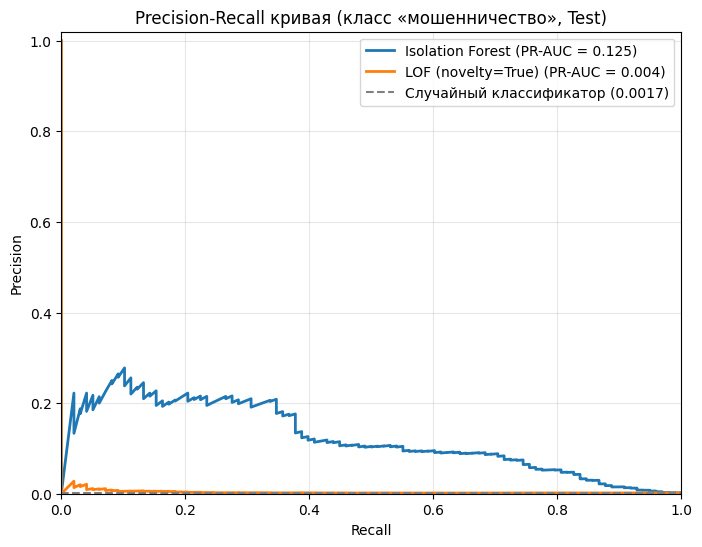

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, scores in [("Isolation Forest", iso_scores), ("LOF (novelty=True)", lof_scores)]:
    p, r, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    ax.plot(r, p, lw=2, label=f"{name} (PR-AUC = {ap:.3f})")

baseline = y_test.mean()
ax.axhline(baseline, color="gray", ls="--", label=f"Случайный классификатор ({baseline:.4f})")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall кривая (класс «мошенничество», Test)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend()
plt.show()


In [14]:
best = results["PR-AUC (AP)"].idxmax()
print(f"Лучшая модель по PR-AUC: {best}")
print(f"  Isolation Forest : PR-AUC = {results.loc['Isolation Forest', 'PR-AUC (AP)']:.4f}, F1 = {results.loc['Isolation Forest', 'F1 (fraud)']:.4f}")
print(f"  LOF              : PR-AUC = {results.loc['LOF (novelty=True)', 'PR-AUC (AP)']:.4f}, F1 = {results.loc['LOF (novelty=True)', 'F1 (fraud)']:.4f}")


Лучшая модель по PR-AUC: Isolation Forest
  Isolation Forest : PR-AUC = 0.1254, F1 = 0.2400
  LOF              : PR-AUC = 0.0035, F1 = 0.0203


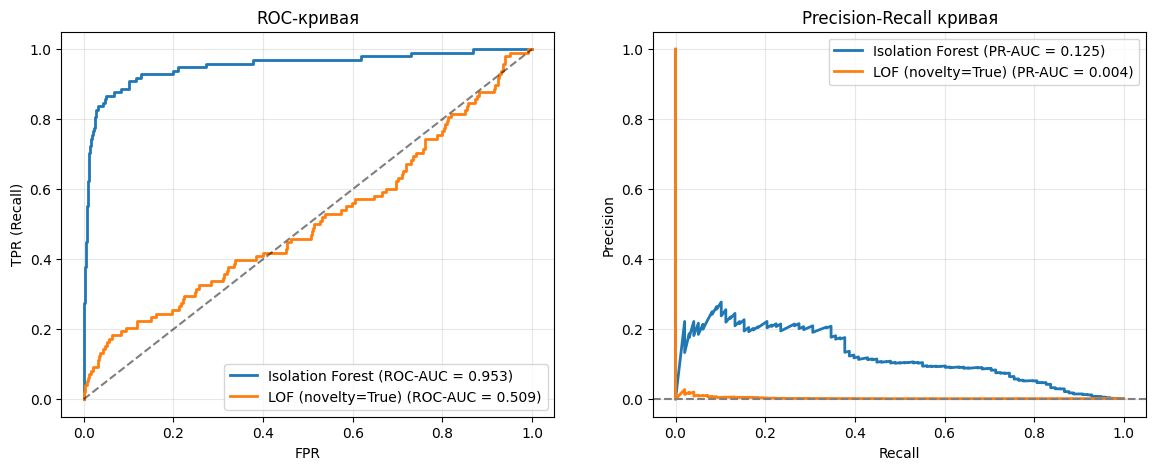

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, scores in [("Isolation Forest", iso_scores), ("LOF (novelty=True)", lof_scores)]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (ROC-AUC = {roc_auc_score(y_test, scores):.3f})")
    p, r, _ = precision_recall_curve(y_test, scores)
    axes[1].plot(r, p, lw=2, label=f"{name} (PR-AUC = {average_precision_score(y_test, scores):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set(xlabel="FPR", ylabel="TPR (Recall)", title="ROC-кривая")
axes[1].axhline(y_test.mean(), color="gray", ls="--")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall кривая")
for a in axes:
    a.grid(alpha=0.3)
    a.legend()
plt.show()


In [16]:
n_neg = int((y_test == 0).sum())
n_pos = int((y_test == 1).sum())

for name, scores in [("Isolation Forest", iso_scores), ("LOF (novelty=True)", lof_scores)]:
    p, r, thr = precision_recall_curve(y_test, scores)
    for target in (0.5, 0.8):
        idx = np.where(r[:-1] >= target)[0][-1]
        flagged = int((scores >= thr[idx]).sum())
        tp = int(round(p[idx] * flagged))
        fp = flagged - tp
        print(f"{name:20s} Recall>={target:.0%}: Precision = {p[idx]:.4f}, "
              f"помечено {flagged}, из них ложных {fp} ({fp / n_neg:.3%} от всех нормальных)")

print(f"\nНаивная модель «всё нормально» даёт accuracy = {1 - y_test.mean():.4%}, но Recall = 0.")


Isolation Forest     Recall>=50%: Precision = 0.1045, помечено 469, из них ложных 420 (0.739% от всех нормальных)
Isolation Forest     Recall>=80%: Precision = 0.0528, помечено 1497, из них ложных 1418 (2.494% от всех нормальных)
LOF (novelty=True)   Recall>=50%: Precision = 0.0017, помечено 29202, из них ложных 29153 (51.268% от всех нормальных)
LOF (novelty=True)   Recall>=80%: Precision = 0.0017, помечено 46233, из них ложных 46154 (81.166% от всех нормальных)

Наивная модель «всё нормально» даёт accuracy = 99.8280%, но Recall = 0.


In [17]:
def predict_with_contamination(model, scores_test, ref_scores, c):
    threshold = np.percentile(ref_scores, 100 * c)
    return ((-scores_test) < threshold).astype(int)

iso_ref = iso.score_samples(X_train_normal)
lof_ref = lof.negative_outlier_factor_

rows = []
for c in [0.01, round(fraud_rate_train, 5), 0.001]:
    for name, scores, ref in [("Isolation Forest", iso_scores, iso_ref),
                              ("LOF (novelty=True)", lof_scores, lof_ref)]:
        pred = predict_with_contamination(None, scores, ref, c)
        rows.append({
            "contamination": c,
            "Модель": name,
            "Помечено": int(pred.sum()),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1 (fraud)": f1_score(y_test, pred, zero_division=0),
        })

contam_table = pd.DataFrame(rows).set_index(["contamination", "Модель"])
contam_table


Помечено  Precision  Recall  F1 (fraud)
contamination Модель                                                     
0.0100        Isolation Forest         675     0.0919  0.6327      0.1604
              LOF (novelty=True)       519     0.0096  0.0510      0.0162
0.0017        Isolation Forest         127     0.2126  0.2755      0.2400
              LOF (novelty=True)        99     0.0202  0.0204      0.0203
0.0010        Isolation Forest          79     0.2025  0.1633      0.1808
              LOF (novelty=True)        67     0.0000  0.0000      0.0000

На этом запуске лучше сработал Isolation Forest: PR-AUC = 0.1254 и F1 = 0.2400 против PR-AUC = 0.0035 и F1 = 0.0203 у LOF. Recall также выше: 0.2755 против 0.0204.ROC-AUC Isolation Forest равен 0.9528, но при сильном дисбалансе даже сотни ложных срабатываний дают небольшой FPR, потому что нормальных транзакций очень много. Precision–Recall AUC лучше показывает качество поиска редкого класса.При снижении contamination с 0.1729% до 0.1% Recall Isolation Forest снизился с 0.2755 до 0.1633, Precision — с 0.2126 до 0.2025. У LOF Recall снизился с 0.0204 до 0, Precision — с 0.0202 до 0. Значит, на этом запуске порог 0.1% снизил обе метрики.